In [23]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [24]:
load_dotenv()

True

In [25]:
model=ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [26]:
class Blog(TypedDict):
    topic:str
    outline:str
    blog:str

In [27]:
def generate_outLine(state:Blog)->Blog:
    input=state['topic']
    prompt=f"generate a 20 words outline for the blog on the topic {input}"
    state['outline']=model.invoke(prompt).content
    return state


In [28]:
def generate_blog(state:Blog)->Blog:
    input_title=state['topic']
    input_outline=state['outline']
    prompt=f"generate a blog on the title {input_title} using the following outline {input_outline} of 60 words"
    state['blog']=model.invoke(prompt).content
    return state

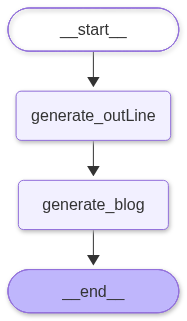

In [29]:
graph=StateGraph(Blog)

graph.add_node("generate_outLine",generate_outLine)
graph.add_node("generate_blog",generate_blog)

graph.add_edge(START,"generate_outLine")
graph.add_edge("generate_outLine","generate_blog")
graph.add_edge("generate_blog",END)

workflow=graph.compile()
workflow

In [30]:
input_state={"topic":"ms dhoni"}
output_state=workflow.invoke(input_state)
print(output_state)

{'topic': 'ms dhoni', 'outline': [{'type': 'text', 'text': 'Here is a 20-word outline for a blog about MS Dhoni:\n\n**Early life, domestic cricket, iconic captaincy, World Cup glory, legendary finishing, calm leadership, IPL dominance, retirement, and enduring sporting legacy.**', 'extras': {'signature': 'EqEBCp4BAWkUfRNPRo8FL61URZ+godRygQLxSNYQcHx+/xIYdH9xX1BXYWIzK6N4CCfXJBsCIr+CxYJ0ZGfuSWDIJPGchhU4yALf1sG/iRGa/GlgTe+MQK6lkfoQwymw+U3jnlQOSbF5NfHK6Zac2HkQo/1nljQ1Ci/HK6XVPNgjInJfxfiW81FZKbMrIyxxHxX+WC2wxpVg0/v/LtjUSnxYTzw='}}], 'blog': [{'type': 'text', 'text': 'From humble beginnings to global icon, MS Dhoni transformed Indian cricket. His calm leadership steered the team to historic World Cup glory, while his legendary finishing skills defined an era. Beyond his unmatched IPL dominance and tactical brilliance, Dhoni’s journey remains a testament to grit. His enduring legacy continues to inspire millions, cementing his status as a true sporting legend.', 'extras': {'signature': 'EqEBCp